In [1]:
# Import necessary libraries

from matplotlib import pyplot as plt

# Assuming access_times is a custom module with necessary functions
import access_times



In [7]:
def daily_accesses(df, label):
    """
    Generates visualizations for daily last access counts.
    
    Parameters:
    - daily_counts: A Series containing the counts of  accesses per day.
    """
    plt.figure(figsize=(12, 6))
    plt.fill_between(df.index, df.values, step="pre", alpha=0.4)
    plt.plot(df.index, df.values, label=label)
    plt.title('File Access Distribution Over Days')
    plt.xlabel('Days Since System Build')
    plt.ylabel('Number of Files Accessed')
    plt.legend()
    plt.grid(True)
    plt.show()



Total number of entries in df: 236921
Count array: [236921, 0, 0, 0]
Total number of entries in df after days: 236921
Count array: [236921, 0, 0, 0]
Total number of entries in rp_merged_df : 269109
Count array: [269109, 0, 0, 0]
Total number of entries in rp_merged_df : 79357
Count array: [79357, 0, 0, 0]
Total number of entries in packages_df : 79357
Count array: [0]


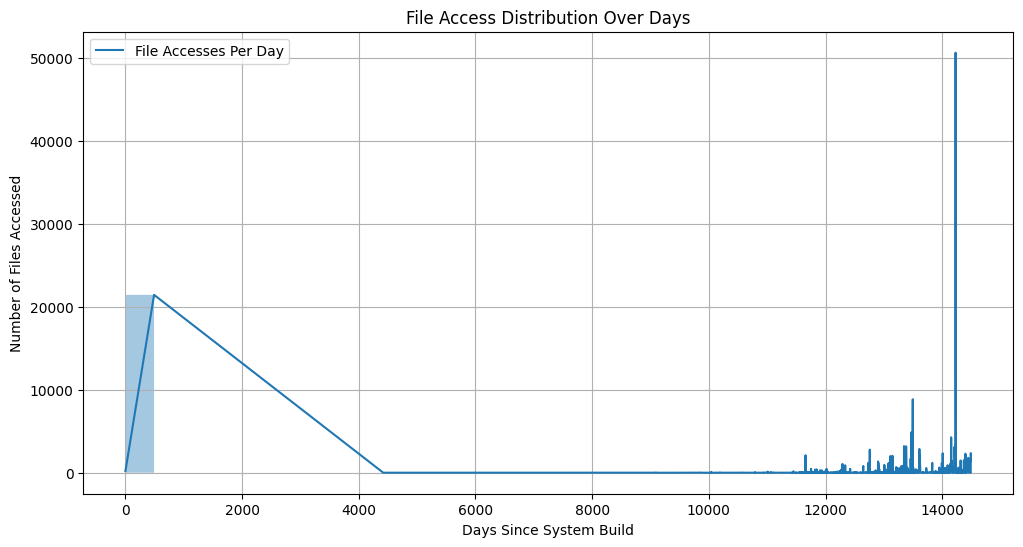

TypeError: unhashable type: 'numpy.ndarray'

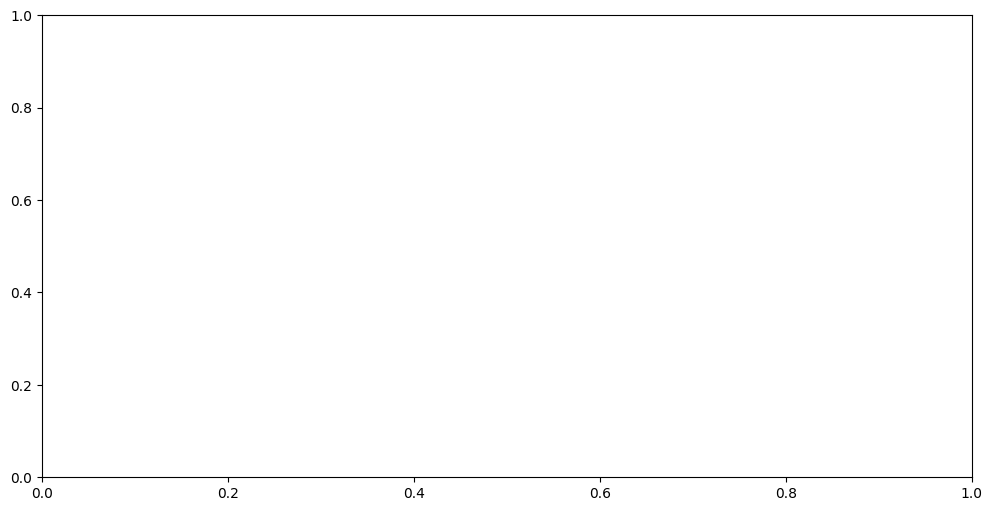

In [8]:
import os

input_dir = "insights-rand-1"
file_packages_suffix = "all_package_files.log"
file_usage_suffix = "usage.log"
package_file_path = os.path.join(input_dir, f"{input_dir}-{file_packages_suffix}")
if not os.path.exists(package_file_path):
    print(f"{file_packages_suffix} does not exist in {input_dir}")
    exit(1)    
usage_file_path = os.path.join(input_dir, f"{input_dir}-{file_usage_suffix}")
if not os.path.exists(usage_file_path):
    print(f"{file_packages_suffix} does not exist in {input_dir}")
    exit(1)    


reporting_intervals = [13,28,45 ]
# Process files
files_packages_df,  file_accesses_per_day, merged_df, unneeded_files, version = access_times.create_package_dframes(package_file_path, usage_file_path)

# Generate visualizations
daily_accesses(file_accesses_per_day, "File Accesses Per Day")

    # Generate reports
merged_df_sorted = merged_df.sort_values("access_time")
latest_access_per_time = merged_df_sorted[["access_time", "package"]].groupby('access_time').tail(1)


In [9]:
# select file matching //boot/vmlinuz-* with the latest access time
#osver = daily_counts[daily_counts['path'].str.contains('//boot/vmlinuz-.*', regex=True)].groupby('path').max().reset_index()
file_accesses_per_day.info(verbose=True, show_counts=True, memory_usage="deep")
file_accesses_per_day.head(20)

<class 'pandas.core.series.Series'>
Index: 1825 entries, 0 to 14491
Series name: None
Non-Null Count  Dtype
--------------  -----
1825 non-null   int64
dtypes: int64(1)
memory usage: 28.5 KB


access_time_days_normalized
0         204
491     21427
4419        2
4471        2
4560        3
5353        2
5509        2
5543        3
6165        2
6269        2
6337        2
6689        2
7485        3
7654        1
7661        2
7705        4
7842        4
8010        2
8081        3
8187        1
dtype: int64

In [10]:
from shlex import join

#  each package has multiple rows  display only the 20 packages with the largest access times records without duplicates
packages = (latest_access_per_time[["access_time", "package"]].drop_duplicates(["package"]))
never_include_packages = ["base-files", "coreutils"]  # replace with your list of package names
filtered_packages = packages[~packages["package"].isin(never_include_packages)]
dpkg_commands = [ pkg for pkg in filtered_packages["package"]]
print('20 packages over 45 days old ')

# print each command
print('sudo dpkg -r ')
print(" ".join(dpkg_commands[:10]))
print(" ".join(dpkg_commands[-10:]))

20 packages over 45 days old 
sudo dpkg -r 
netbase libaudit-common screen libattr1:amd64 apparmor bsdmainutils console-setup-linux cron language-selector-common ufw
libacl1:amd64 libpipeline1:amd64 liblz4-1:amd64 motd-news-config libsigsegv2:amd64 libmpdec2:amd64 libpsl5:amd64 libpolkit-gobject-1-0:amd64 libappstream4:amd64 command-not-found


In [11]:
packages.info(verbose=True, show_counts=True, memory_usage="deep")

<class 'pandas.core.frame.DataFrame'>
Index: 476 entries, 137502 to 188701
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   access_time  476 non-null    object
 1   package      476 non-null    object
dtypes: object(2)
memory usage: 51.4 KB


In [12]:
print (packages['package'].str.len().sum())
packages_dict = {package: {} for package in packages['package']}
print(packages_dict)


6471
{'netbase': {}, 'libaudit-common': {}, 'screen': {}, 'libattr1:amd64': {}, 'apparmor': {}, 'bsdmainutils': {}, 'console-setup-linux': {}, 'cron': {}, 'language-selector-common': {}, 'ufw': {}, 'libnewt0.52:amd64': {}, 'gawk': {}, 'procps': {}, 'xdg-user-dirs': {}, 'coreutils': {}, 'software-properties-common': {}, 'apt': {}, 'apt-utils': {}, 'at': {}, 'bolt': {}, 'byobu': {}, 'mime-support': {}, 'python3-chardet': {}, 'kbd': {}, 'debconf': {}, 'distro-info': {}, 'fwupd': {}, 'diffutils': {}, 'cloud-guest-utils': {}, 'eject': {}, 'gettext-base': {}, 'file': {}, 'libglib2.0-bin': {}, 'groff-base': {}, 'htop': {}, 'info': {}, 'python3-jsonschema': {}, 'python3-keyring': {}, 'psmisc': {}, 'ucf': {}, 'less': {}, 'linux-base': {}, 'iproute2': {}, 'initramfs-tools-core': {}, 'lsof': {}, 'pciutils': {}, 'usbutils': {}, 'ltrace': {}, 'man-db': {}, 'mawk': {}, 'mtr-tiny': {}, 'ftp': {}, 'pastebinit': {}, 'pinentry-curses': {}, 'packagekit-tools': {}, 'run-one': {}, 'sbsigntool': {}, 'sg3-ut

In [ ]:
6471/(80*24)
